## pymatgen

pymatgenはmaterials projectで作成された物質を扱うPythonライブラリです。

pymatgenの簡単な紹介を行います。

### 原子座標


In [1]:
import sys
import os
from pymatgen.core import Structure
from pymatgen.io.cif import CifWriter
from pymatgen.io.xcrysden import XSF


def fileconvert2cif(file1, file2):
    """
    file format conversion
    ref.s
    http://pymatgen.org/usage.html

    @param file1 : input filename, any formats pymatgen accepts
    @param file2 : cif output filename
    """
    tmpfilename = "__temp__.cif"

    def write2cif(f1, f2):
        structure = Structure.from_file(f1)
        w = CifWriter(structure)
        w.write_file(f2)

        return structure

    def write2xsf(f1, f2):
        structure = Structure.from_file(f1)

        xsf = XSF(structure)
        s = xsf.to_string()
        with open(f2, "wb") as f:
            f.write(s)

        return structure
    _ = write2cif(file1, tmpfilename)
    """
    run twice to make atoms inside the cell automatically.
    """
    structure = write2cif(tmpfilename, file2)

    os.remove(tmpfilename)
    return structure


os.makedirs("junk", exist_ok=True)
structure = fileconvert2cif("../data/Fe4_xsf/hcp.xsf", "junk/tmp1.cif")


/home/kino/miniforge3/envs/pymc_env/lib/python3.14/site-packages/pymatgen/io/cif.py:1904: UserWarning: Issues encountered while parsing CIF: 2 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  return parser.parse_structures(primitive=primitive)[0]


In [2]:
structure

Structure Summary
Lattice
    abc : 2.46933537 4.27701432 3.88751984
 angles : 90.0 90.0 90.0
 volume : 41.05758493325662
      A : 2.46933537 0.0 1.5120318284459226e-16
      B : 6.877963600983317e-16 4.27701432 2.618915948447697e-16
      C : 0.0 0.0 3.88751984
    pbc : True True True
PeriodicSite: Fe0 (Fe) (1.235, 0.7128, 2.916) [0.5, 0.1667, 0.75]
PeriodicSite: Fe1 (Fe) (4.585e-16, 2.851, 2.916) [0.0, 0.6667, 0.75]
PeriodicSite: Fe2 (Fe) (1.235, 3.564, 0.9719) [0.5, 0.8333, 0.25]
PeriodicSite: Fe3 (Fe) (2.293e-16, 1.426, 0.9719) [0.0, 0.3333, 0.25]

In [3]:
print(len(structure))
for s in structure:
    print(s)

4
[1.23466769 0.71283573 2.91563988] Fe
[4.58530907e-16 2.85134288e+00 2.91563988e+00] Fe
[1.23466769 3.56417859 0.97187996] Fe
[2.29265453e-16 1.42567144e+00 9.71879960e-01] Fe


In [4]:
def show_neighbors(structure):
    rcut = 3.0
    for s in structure:
        print("center", s.coords, s.specie)
        nn = structure.get_neighbors(s, rcut)
        print("number of atoms", len(nn))
        for n in nn:
            print("cart", n[0].coords, n[0].specie, "distance", n[1])


show_neighbors(structure)


center [1.23466769 0.71283573 2.91563988] Fe
number of atoms 12
cart [-2.29265453e-16 -1.42567144e+00  2.91563988e+00] Fe distance 2.4693353815815913
cart [2.29265453e-16 1.42567144e+00 9.71879960e-01] Fe distance 2.4105480004273288
cart [2.29265453e-16 1.42567144e+00 4.85939980e+00] Fe distance 2.4105480004273288
cart [4.58530907e-16 2.85134288e+00 2.91563988e+00] Fe distance 2.4693353568882355
cart [-1.23466768  0.71283573  2.91563988] Fe distance 2.4693353700000005
cart [ 1.23466768 -0.71283573  0.97187996] Fe distance 2.410548021245718
cart [ 2.46933537 -1.42567144  2.91563988] Fe distance 2.4693353815815904
cart [ 1.23466768 -0.71283573  4.8593998 ] Fe distance 2.410548021245717
cart [2.46933537 1.42567144 0.97187996] Fe distance 2.4105480004273288
cart [2.46933537 1.42567144 4.8593998 ] Fe distance 2.410548000427329
cart [2.46933537 2.85134288 2.91563988] Fe distance 2.469335356888236
cart [3.70400306 0.71283573 2.91563988] Fe distance 2.46933537
center [4.58530907e-16 2.85134288

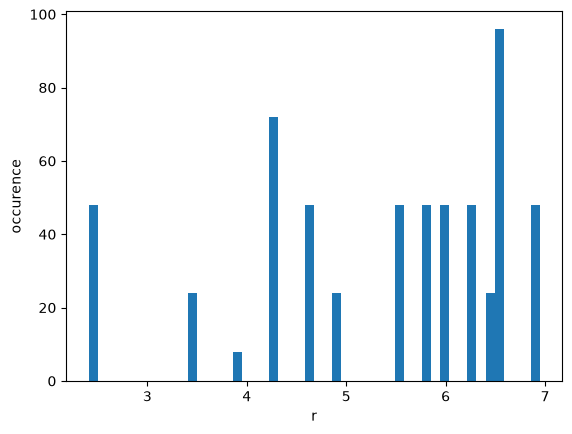

[1.         1.12244898 1.24489796 1.36734694 1.48979592 1.6122449
 1.73469388 1.85714286 1.97959184 2.10204082 2.2244898  2.34693878
 2.46938776 2.59183673 2.71428571 2.83673469 2.95918367 3.08163265
 3.20408163 3.32653061 3.44897959 3.57142857 3.69387755 3.81632653
 3.93877551 4.06122449 4.18367347 4.30612245 4.42857143 4.55102041
 4.67346939 4.79591837 4.91836735 5.04081633 5.16326531 5.28571429
 5.40816327 5.53061224 5.65306122 5.7755102  5.89795918 6.02040816
 6.14285714 6.26530612 6.3877551  6.51020408 6.63265306 6.75510204
 6.87755102 7.        ]


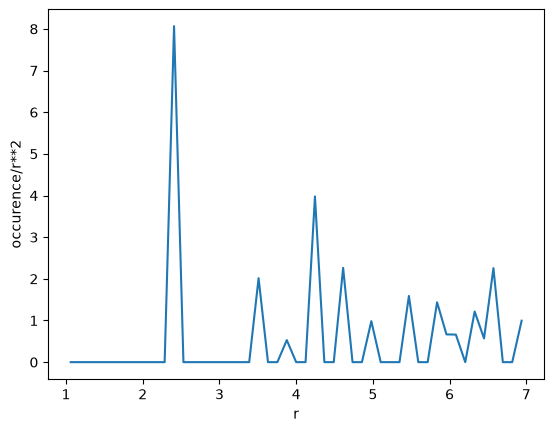

In [5]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline


def plot_rdf(structure, rcut):
    """
    plot radial distribution function (rdf) with the distance list given by pymatgen library

    @param structure : pymatgen structure
    @param  rcut : cutoff distance
    """
    distancelist = []
    for s in structure:
        nn = structure.get_neighbors(s, rcut)
        for n in nn:
            distancelist.append(n[1])

    def plot_hist(distancelist, bins=50):
        """
        histgram plot

        @param distancelist : a list of distances
        @param bins : a list of bins
        """
        plt.xlabel("r")
        plt.ylabel("occurence")
        """
        histgram library of matplotlib
        """
        plt.hist(distancelist, bins=bins)
        plt.show()

    plot_hist(distancelist)

    def plot_rdf_div_r2(distancelist, rcut, xmin=1.0, bins=50):
        """
        multiply histgram by 1/r**2
        and plot it

        @param distancelist : a list of distance
        @param xrange : 1d array [2], min and max
        @param bins : number of bins of histgram
        """
        bins = np.linspace(xmin, rcut, bins)
        print(bins)
        index = np.digitize(distancelist, bins)
        """
        add to hist array
        """
        hist = np.zeros((len(bins)))
        for i, d in zip(index, distancelist):
            if i > 0 and i < len(bins):
                if bins[i-1] < d and d < bins[i]:
                    hist[i] += 1.0/d**2
                    continue
            print("warning i", i, d)
        """
        visualization
        """
        plt.xlabel("r")
        plt.ylabel("occurence/r**2")
        """
        use the middle point for x points
        """
        bins_mid = (bins[0:-1]+bins[1:])*0.5

        plt.plot(bins_mid, hist[1:])
        plt.show()

    plot_rdf_div_r2(distancelist, rcut)


plot_rdf(structure, rcut=7.0)



### 分子式

分子式の解釈,元素の説明変数取得ができます。

In [6]:
from pymatgen.core.composition import Composition
comp = Composition("(FeO3Cl)Cl3.5")
print("str(comp)=", str(comp))
print("comp.num_atoms=", comp.num_atoms)
print("comp.as_dict()=", comp.as_dict())
print("comp.weight=", comp.weight)


str(comp)= Fe1 O3 Cl4.5
comp.num_atoms= 8.5
comp.as_dict()= {'Fe': 1.0, 'O': 3.0, 'Cl': 4.5}
comp.weight= 263.3817 amu



### 元素

元素の物性値を取得することができます。

In [7]:
from pymatgen.core.periodic_table import Element
elm = Element("Fe")
print("elm.atomic_radius_calculated=", elm.atomic_radius_calculated)
print("elm.liquid_range=", elm.liquid_range)
print("elm.X(Pauling electronegativity)=", elm.X)


elm.atomic_radius_calculated= 1.56 ang
elm.liquid_range= 1323.0 K
elm.X(Pauling electronegativity)= 1.83


最後にcompsitionから各原元素を得てその元素の特性を表示する例を示します。

In [8]:
comp = Composition("(Fe(CN)6)(CH3)3")
for key in comp:
    elm = Element(key)
    print("element={}, fraction={}, density_of_solid={}, molar_volume={}".format(
        key, comp[key], elm.density_of_solid, elm.molar_volume))


element=Fe, fraction=1.0, density_of_solid=7874.0 kg m^-3, molar_volume=7.09 cm^3 mol^-1
element=C, fraction=9.0, density_of_solid=2267.0 kg m^-3, molar_volume=5.29 cm^3 mol^-1
element=N, fraction=6.0, density_of_solid=None, molar_volume=13.54 cm^3 mol^-1
element=H, fraction=9.0, density_of_solid=None, molar_volume=11.42 cm^3 mol^-1


/tmp/mi-in-place.WyFyuX/ipykernel_12580/1665544018.py:5: UserWarning: No data available for density_of_solid for N
  key, comp[key], elm.density_of_solid, elm.molar_volume))
/tmp/mi-in-place.WyFyuX/ipykernel_12580/1665544018.py:5: UserWarning: No data available for density_of_solid for H
  key, comp[key], elm.density_of_solid, elm.molar_volume))
